In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

Experiment

In [68]:
steps = 20000
K = 10 #arms
D = 5 #context dimsz

Hyperparams

In [69]:
RIDGE = 1.0 #L2 regularization
ALPHA = 1.2 #UCB бонус

EPS0 = 0.1
EPS_MIN = 0.02
EPS_DECAY = 0.0008

WIN = 400 #window length (играйся 300–800)
TS_V = 1.0  #масштаб ковариации

# Среда (non stationarity)
SIGMA_DRIFT = 0.01 #slow dr
shift = steps // 2 #rapid shift in the middle

Context (features)

In [70]:
t = np.arange(steps)
X = np.random.uniform(0, 1, size=(steps, D)).astype(np.float64)
X[:, 0] = 0.5 + 0.5*np.sin(2*np.pi*t/365)   # сезонность


Environment

In [71]:
theta_t = np.random.standard_normal((K, D + 1)).astype(np.float64)

def logistic(z): return 1.0 / (1.0 + np.exp(-z))

def prob_of_arm(a, x, theta):
    return logistic(theta[a, 0] + theta[a, 1:] @ x)

def oracle(x, theta):
    ps = np.array([prob_of_arm(a, x, theta) for a in range(K)])
    return int(np.argmax(ps)), float(ps.max()), ps

def evolve_theta(theta, step):
    theta = theta + np.random.normal(0.0, SIGMA_DRIFT, size=theta.shape) #
    if step == shift:
        theta = np.random.standard_normal((K, D + 1))
    return theta


Matrix update

In [72]:
def sm_update_inv(A_inv, u): #(Шерман–Моррисон)
    Au = A_inv @ u
    denom = 1.0 + u.T @ Au
    return A_inv - np.outer(Au, Au) / denom

def sm_downdate_inv(A_inv, u):#(ранг-1 downdate)
    Au = A_inv @ u
    denom = 1.0 - u.T @ Au
    if denom <= 1e-9: denom = 1e-9
    return A_inv + np.outer(Au, Au) / denom


Algorithms

In [73]:
class EGREEDY:
    def __init__(self, d=D, K=K, ridge=RIDGE, eps0=EPS0, eps_min=EPS_MIN, eps_decay=EPS_DECAY):
        self.K, self.d = K, d
        self.eps0, self.eps_min, self.eps_decay = eps0, eps_min, eps_decay
        self.t = 0
        self.A_inv = np.array([np.linalg.inv(ridge*np.eye(d)) for _ in range(K)])
        self.b = np.zeros((K, d))

    def _eps_t(self): return max(self.eps_min, self.eps0 * (1.0 - self.eps_decay * self.t))

    def select(self, x):
        self.t += 1
        if np.random.rand() < self._eps_t():#explore
            return np.random.randint(0, self.K)
        means = [x @ (self.A_inv[a] @ self.b[a]) for a in range(self.K)]
        return int(np.argmax(means)) #exploit

    def update(self, a, x, r):
        self.A_inv[a] = sm_update_inv(self.A_inv[a], x)
        self.b[a] += r * x

    def theta_hat_all(self): return np.array([self.A_inv[a] @ self.b[a] for a in range(self.K)])


class UCB:
    """LinUCB: mu + alpha * sqrt(x^T A^{-1} x)."""
    def __init__(self, d=D, K=K, ridge=RIDGE, alpha=ALPHA):
        self.K, self.d, self.alpha = K, d, alpha
        self.A_inv = np.array([np.linalg.inv(ridge*np.eye(d)) for _ in range(K)])
        self.b = np.zeros((K, d))

    def select(self, x):
        scores = []
        for a in range(self.K):
            th = self.A_inv[a] @ self.b[a]
            mu = x @ th
            s  = np.sqrt(x @ self.A_inv[a] @ x)
            scores.append(mu + self.alpha * s)
        return int(np.argmax(scores))

    def update(self, a, x, r):
        self.A_inv[a] = sm_update_inv(self.A_inv[a], x)
        self.b[a] += r * x

    def theta_hat_all(self): return np.array([self.A_inv[a] @ self.b[a] for a in range(self.K)])


class SWLinTS:#быстро забывает старое
    def __init__(self, d=D, K=K, ridge=RIDGE, v=TS_V, window=WIN):
        self.K, self.d, self.v, self.window = K, d, v, window
        self.buffers = [deque(maxlen=window) for _ in range(K)]
        self.A_inv = np.array([np.linalg.inv(ridge*np.eye(d)) for _ in range(K)])
        self.b = np.zeros((K, d))

    def select(self, x):
        vals = np.empty(self.K)
        for a in range(self.K):
            mean = self.A_inv[a] @ self.b[a]
            cov  = (self.v**2) * self.A_inv[a]
            cov  = 0.5*(cov + cov.T)# симметризация для устойчивости
            w, U = np.linalg.eigh(cov)
            w = np.clip(w, 1e-8, 1e6)
            cov = (U * w) @ U.T
            th_s = np.random.multivariate_normal(mean, cov)
            vals[a] = float(x @ th_s)
        return int(np.argmax(vals))

    def update(self, a, x, r):
        if len(self.buffers[a]) == self.window:
            x_old, r_old = self.buffers[a][0]
            self.A_inv[a] = sm_downdate_inv(self.A_inv[a], x_old)
            self.b[a] -= r_old * x_old
        self.buffers[a].append((x, r))
        self.A_inv[a] = sm_update_inv(self.A_inv[a], x)
        self.b[a] += r * x

    def theta_hat_all(self): return np.array([self.A_inv[a] @ self.b[a] for a in range(self.K)])

Simulations 20 000 steps

In [74]:
algos = {
    "Epsilon-Greedy": EGREEDY(),
    "UCB":            UCB(),
    "Thompson Sampling": SWLinTS(),   
}

hist = {n: {"reward": np.zeros(steps, int),
            "regret": np.zeros(steps, float)} for n in algos}
true_prob_sum = np.zeros(K, float)

for step in range(steps):
    x = X[step]
    a_star, best_p, ps = oracle(x, theta_t)
    true_prob_sum += ps

    for name, algo in algos.items():
        a = algo.select(x)
        r = np.random.binomial(1, ps[a])
        hist[name]["reward"][step] = r
        hist[name]["regret"][step] = best_p - ps[a]
        algo.update(a, x, r)

    theta_t = evolve_theta(theta_t, step)

true_prob_avg = true_prob_sum / steps


Summary: before / after

In [75]:
rows = [[n, hist[n]["regret"].sum(), hist[n]["reward"].mean()] for n in algos]
df_summary = pd.DataFrame(rows, columns=["Algorithm","Cumulative Regret (↓)","Avg CTR"]).sort_values("Cumulative Regret (↓)")
print(df_summary)

split = shift
rows_ba = []
for n in algos:
    r = hist[n]["reward"]
    rg = hist[n]["regret"].cumsum()
    rows_ba.append([n, r[:split].mean(), r[split:].mean(), rg[split-1], rg[-1]-rg[split-1]])
df_before_after = pd.DataFrame(rows_ba,
    columns=["Algorithm","CTR before 10k","CTR after 10k","Regret before 10k","Regret after 10k"])
print()
print(df_before_after)

           Algorithm  Cumulative Regret (↓)  Avg CTR
2  Thompson Sampling            1411.132591  0.88245
0     Epsilon-Greedy            1551.934193  0.87700
1                UCB            1751.560396  0.86820

           Algorithm  CTR before 10k  CTR after 10k  Regret before 10k  \
0     Epsilon-Greedy          0.8885         0.8655         414.245858   
1                UCB          0.8618         0.8746         637.995715   
2  Thompson Sampling          0.8339         0.9310         891.188764   

   Regret after 10k  
0       1137.688335  
1       1113.564680  
2        519.943828  


Plots

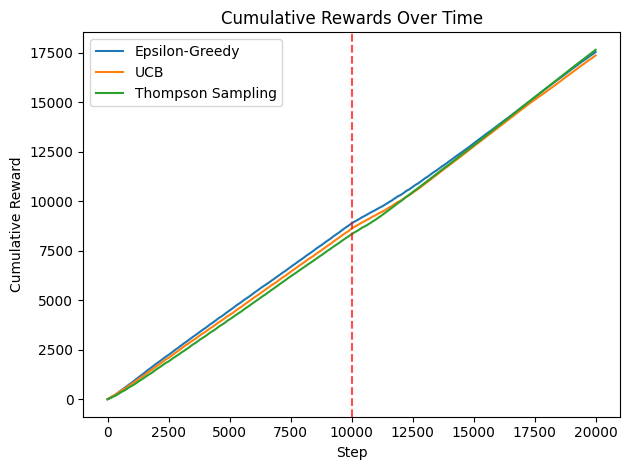

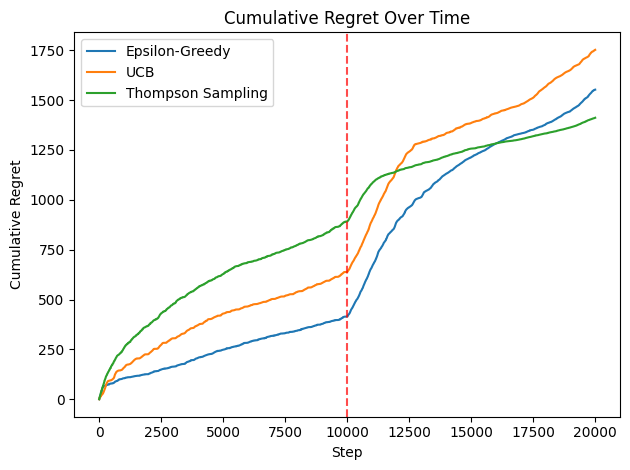

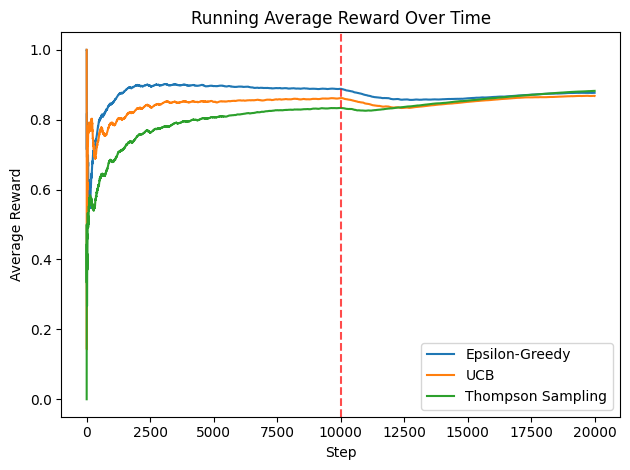

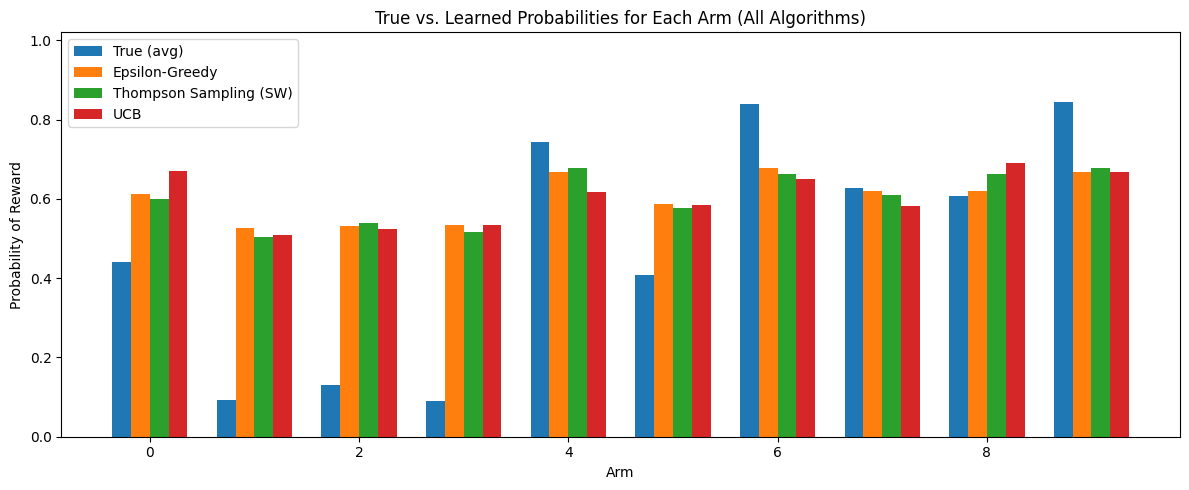

In [76]:
steps = np.arange(steps)

# (1) Cumulative Rewards Over Time
plt.figure()
for n in algos:
    plt.plot(steps, np.cumsum(hist[n]["reward"]), label=n)
plt.axvline(shift, color="red", linestyle="--", alpha=0.7)  # линия шока
plt.xlabel("Step"); plt.ylabel("Cumulative Reward")
plt.title("Cumulative Rewards Over Time")
plt.legend(); plt.tight_layout(); plt.show()

# (2) Cumulative Regret Over Time
plt.figure()
for n in algos:
    plt.plot(steps, np.cumsum(hist[n]["regret"]), label=n)
plt.axvline(shift, color="red", linestyle="--", alpha=0.7)
plt.xlabel("Step"); plt.ylabel("Cumulative Regret")
plt.title("Cumulative Regret Over Time")
plt.legend(); plt.tight_layout(); plt.show()

# (3) Running Average Reward Over Time (глобальная средняя)
plt.figure()
for n in algos:
    r = hist[n]["reward"].astype(float)
    avg = np.cumsum(r) / (np.arange(len(r)) + 1.0)
    plt.plot(steps, avg, label=n)
plt.axvline(shift, color="red", linestyle="--", alpha=0.7)
plt.xlabel("Step"); plt.ylabel("Average Reward")
plt.title("Running Average Reward Over Time")
plt.legend(); plt.tight_layout(); plt.show()

# (4) True vs. Learned Probabilities for Each Arm (All Algorithms)
def learned_probs_from(algo):
    th = algo.theta_hat_all()                          # (K, d)
    preds = 1.0 / (1.0 + np.exp(-(X @ th.T)))         # (T, K)
    return preds.mean(axis=0)                          # среднее по всем контекстам

arms = np.arange(K); width = 0.18
plt.figure(figsize=(12,5))
plt.bar(arms - 1.5*width, true_prob_avg, width, label="True (avg)")
plt.bar(arms - 0.5*width, learned_probs_from(algos["Epsilon-Greedy"]), width, label="Epsilon-Greedy")
plt.bar(arms + 0.5*width, learned_probs_from(algos["Thompson Sampling"]), width, label="Thompson Sampling (SW)")
plt.bar(arms + 1.5*width, learned_probs_from(algos["UCB"]), width, label="UCB")
plt.ylim(0, 1.02); plt.xlabel("Arm"); plt.ylabel("Probability of Reward")
plt.title("True vs. Learned Probabilities for Each Arm (All Algorithms)")
plt.legend(); plt.tight_layout(); plt.show()